# Sprint 5 — Tópico 1 e Tópico 2: Revisão do Pipeline Congelado e Comparativo de Modelos

**Trilha:** C — Risco de baixa produtividade agrícola (Soja em Sorriso - MT)  
**Responsável (Cards Trello):** Samuel Allan Nunes da Cunha (SA)  

## Objetivos:
- **TÓPICO 1 (Revisão do Split e Pipeline Congelado):** Reconfirmar o split temporal 2015–2022 (treino) e 2023–2024 (teste), validar a ausência de vazamento temporal e carregar o  congelado na Sprint 4.
- **TÓPICO 2 (Comparativo de Modelos):** Avaliar na mesma partição os 3 baselines da Sprint 4 (, , ) e pelo menos dois novos classificadores com complexidade compatível com =8$ ( regularizada L2 e  rasa, ambos com ).

In [1]:
import pandas as pd
import numpy as np
import joblib
from pathlib import Path

from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    confusion_matrix, classification_report,
    recall_score, precision_score, f1_score, accuracy_score
)
import matplotlib.pyplot as plt

print("Bibliotecas carregadas com sucesso!")

/home/v2saude/Área de Trabalho/bx_produtividade_agricola/.venv/lib/python3.8/site-packages/xgboost/core.py:265: FutureWarning: Your system has an old version of glibc (< 2.28). We will stop supporting Linux distros with glibc older than 2.28 after **May 31, 2025**. Please upgrade to a recent Linux distro (with glibc 2.28+) to use future versions of XGBoost.
Note: You have installed the 'manylinux2014' variant of XGBoost. Certain features such as GPU algorithms or federated learning are not available. To use these features, please upgrade to a recent Linux distro with glibc 2.28+, and install the 'manylinux_2_28' variant.
  warnings.warn(


Bibliotecas carregadas com sucesso!


## 1. Tópico 1 — Revisão dos Dados, Split Temporal e Pipeline Congelado

Garantia anti-vazamento:
- Partição de treino: 2015 a 2022 ({train} = 8$ safras)
- Partição de teste: 2023 a 2024 ({test} = 2$ safras)
- As features (, , , ) encerram seu cálculo em 28 de fevereiro, antes do fim da safra oficial.

In [2]:
df = pd.read_csv("../data/processed/dados_modelo.csv")
print(f"Dataset carregado: {df.shape[0]} safras x {df.shape[1]} colunas")

FEATURES = ["deficit_hidrico_solo", "dias_pico_calor", "amplitude_termica", "precipitacao_enchimento"]
TARGET = "quebra_safra"

df_treino = df[df["ano"] <= 2022].copy()
df_teste = df[df["ano"] >= 2023].copy()

X_train, y_train = df_treino[FEATURES], df_treino[TARGET]
X_test, y_test = df_teste[FEATURES], df_teste[TARGET]

print(f"Treino: safras {df_treino['ano'].min()} a {df_treino['ano'].max()} (N = {len(df_treino)}) | Quebras: {y_train.sum()}")
print(f"Teste : safras {df_teste['ano'].min()} a {df_teste['ano'].max()} (N = {len(df_teste)}) | Quebras: {y_test.sum()}")

# Carregar pré-processador congelado na Sprint 4
preprocessor = joblib.load("../models/s4_preprocessor_congelado.joblib")
print("Pré-processador congelado:", preprocessor)


Dataset carregado: 10 safras x 15 colunas
Treino: safras 2015 a 2022 (N = 8) | Quebras: 3
Teste : safras 2023 a 2024 (N = 2) | Quebras: 0
Pré-processador congelado: ColumnTransformer(transformers=[('scaler', StandardScaler(),
                                 ['deficit_hidrico_solo', 'dias_pico_calor',
                                  'amplitude_termica',
                                  'precipitacao_enchimento'])])


## 2. Tópico 2 — Definição dos Classificadores

Montamos os 5 modelos avaliados no mesmo pipeline:
1. **DummyClassifier:** Estratégia de classe mais frequente (baseline ingênuo).
2. **Persistência:** Repete o resultado da safra anterior (baseline temporal).
3. **GaussianNB:** Naive Bayes Gaussiano (baseline probabilístico da Sprint 4).
4. **LogisticRegression:** Regressor linear regularizado L2 com  e =1.0$.
5. **DecisionTreeClassifier:** Árvore rasa (, , ) com interpretabilidade direta.

In [3]:
pipelines = {
    "Dummy (Mais Frequente)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]),
    "GaussianNB (Naive Bayes)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", GaussianNB())
    ]),
    "Logistic Regression (L2)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(C=1.0, class_weight="balanced", random_state=42))
    ]),
    "Decision Tree (Rasa)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(max_depth=2, min_samples_leaf=1, class_weight="balanced", random_state=42))
    ])
}

# Treinar modelos que aprendem dos dados com fit exclusivo no treino
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    print(f"Modelo treinado com sucesso no treino: {name}")

Modelo treinado com sucesso no treino: Dummy (Mais Frequente)
Modelo treinado com sucesso no treino: GaussianNB (Naive Bayes)
Modelo treinado com sucesso no treino: Logistic Regression (L2)
Modelo treinado com sucesso no treino: Decision Tree (Rasa)


## 3. Avaliação no Teste Oficial (2023–2024)

No conjunto de teste oficial (=2$, safras 2023 e 2024), ambas as safras foram normais ().
Verificamos as contagens absolutas de acertos e se algum classificador dispara alarme falso.

In [4]:
resultados_teste = []

# 1. Modelos em Pipeline
for name, pipe in pipelines.items():
    preds = pipe.predict(X_test)
    cm = confusion_matrix(y_test, preds, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    resultados_teste.append({
        "Modelo": name,
        "Acurácia Teste": f"{accuracy_score(y_test, preds):.2f}",
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Recall Quebra (C1)": "n/d",
        "Precisão Quebra (C1)": "n/d",
        "F1 Quebra (C1)": "n/d"
    })

# 2. Persistência Temporal no Teste
preds_pers = []
for ano in df_teste["ano"]:
    ano_ant = ano - 1
    val_ant = df[df["ano"] == ano_ant][TARGET].values[0]
    preds_pers.append(val_ant)

cm_pers = confusion_matrix(y_test, preds_pers, labels=[0, 1])
tn, fp, fn, tp = cm_pers.ravel()
resultados_teste.insert(1, {
    "Modelo": "Persistência Temporal",
    "Acurácia Teste": f"{accuracy_score(y_test, preds_pers):.2f}",
    "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    "Recall Quebra (C1)": "n/d",
    "Precisão Quebra (C1)": "n/d",
    "F1 Quebra (C1)": "n/d"
})

df_res_teste = pd.DataFrame(resultados_teste)
print("=== COMPARATIVO NO TESTE OFICIAL (2023–2024) ===")
display(df_res_teste)

=== COMPARATIVO NO TESTE OFICIAL (2023–2024) ===


,Modelo,Acurácia Teste,TN,FP,FN,TP,Recall Quebra (C1),Precisão Quebra (C1),F1 Quebra (C1)
0,Dummy (Mais Frequente),1.00,2,0,0,0,n/d,n/d,n/d
1,Persistência Temporal,1.00,2,0,0,0,n/d,n/d,n/d
2,GaussianNB (Naive Bayes),1.00,2,0,0,0,n/d,n/d,n/d
3,Logistic Regression (L2),1.00,2,0,0,0,n/d,n/d,n/d
4,Decision Tree (Rasa),1.00,2,0,0,0,n/d,n/d,n/d


## 4. Diagnóstico Complementar: Backtest Temporal Expansivo no Treino (2019–2022)

Como o teste oficial não possui eventos de quebra (=1$), realizamos a avaliação em janela temporal expansiva no treino para observar o comportamento de cada modelo diante do evento real de 2021.

In [5]:
safras_backtest = [2019, 2020, 2021, 2022]
preds_backtest = {m: [] for m in list(pipelines.keys()) + ["Persistência Temporal"]}
reais_backtest = []

from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

for safra in safras_backtest:
    df_tr_fold = df[df["ano"] < safra]
    df_te_fold = df[df["ano"] == safra]
    
    y_real = df_te_fold[TARGET].values[0]
    reais_backtest.append(y_real)
    
    # Persistência
    y_ant = df[df["ano"] == (safra - 1)][TARGET].values[0]
    preds_backtest["Persistência Temporal"].append(y_ant)
    
    # Pipeline dinâmico com fit estrito no passado da dobra
    ct_fold = ColumnTransformer([("scaler", StandardScaler(), FEATURES)], remainder="drop")
    
    for name in pipelines.keys():
        if "Dummy" in name:
            clf = DummyClassifier(strategy="most_frequent")
        elif "GaussianNB" in name:
            clf = GaussianNB()
        elif "Logistic" in name:
            clf = LogisticRegression(C=1.0, class_weight="balanced", random_state=42)
        elif "Tree" in name:
            clf = DecisionTreeClassifier(max_depth=2, min_samples_leaf=1, class_weight="balanced", random_state=42)
            
        p_fold = Pipeline([("prep", ct_fold), ("clf", clf)])
        p_fold.fit(df_tr_fold[FEATURES], df_tr_fold[TARGET])
        p_pred = p_fold.predict(df_te_fold[FEATURES])[0]
        preds_backtest[name].append(p_pred)

df_backtest_preds = pd.DataFrame(preds_backtest, index=safras_backtest)
df_backtest_preds["Real (Quebra)"] = reais_backtest
print("=== PREVISÕES POR SAFRA NO BACKTEST EXPANSIVO ===")
display(df_backtest_preds)

=== PREVISÕES POR SAFRA NO BACKTEST EXPANSIVO ===


,Dummy (Mais Frequente),GaussianNB (Naive Bayes),Logistic Regression (L2),Decision Tree (Rasa),Persistência Temporal,Real (Quebra)
2019,0,1,0,1,0,0
2020,0,0,0,0,0,0
2021,0,1,0,1,0,1
2022,0,0,0,0,1,0


In [6]:
res_metricas_backtest = []
for name in df_backtest_preds.columns:
    if name == "Real (Quebra)":
        continue
    y_pred = df_backtest_preds[name]
    cm = confusion_matrix(reais_backtest, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    
    rec = recall_score(reais_backtest, y_pred, pos_label=1, zero_division=0)
    prec = precision_score(reais_backtest, y_pred, pos_label=1, zero_division=0)
    f1 = f1_score(reais_backtest, y_pred, pos_label=1, zero_division=0)
    
    res_metricas_backtest.append({
        "Modelo": name,
        "Recall Quebra (C1)": f"{rec:.2f}",
        "Precisão Quebra (C1)": f"{prec:.2f}",
        "F1 Quebra (C1)": f"{f1:.2f}",
        "TP (Quebra detectada)": tp,
        "FN (Quebra perdida)": fn,
        "FP (Alarme falso)": fp,
        "TN (Normal acertada)": tn
    })

df_tab_backtest = pd.DataFrame(res_metricas_backtest)
print("=== MÉTRICAS NO BACKTEST EXPANSIVO (2019–2022) ===")
display(df_tab_backtest)

=== MÉTRICAS NO BACKTEST EXPANSIVO (2019–2022) ===


,Modelo,Recall Quebra (C1),Precisão Quebra (C1),F1 Quebra (C1),TP (Quebra detectada),FN (Quebra perdida),FP (Alarme falso),TN (Normal acertada)
0,Dummy (Mais Frequente),0.00,0.00,0.00,0,1,0,3
1,GaussianNB (Naive Bayes),1.00,0.50,0.67,1,0,1,2
2,Logistic Regression (L2),0.00,0.00,0.00,0,1,0,3
3,Decision Tree (Rasa),1.00,0.50,0.67,1,0,1,2
4,Persistência Temporal,0.00,0.00,0.00,0,1,1,2


## 5. Visualização e Interpretabilidade da Árvore de Decisão

Como a Árvore de Decisão rasa teve 100% de Recall na quebra de 2021 no backtest, plotamos a árvore treinada no conjunto completo de treino (=8$) para inspecionar os limiares de decisão agronômica.

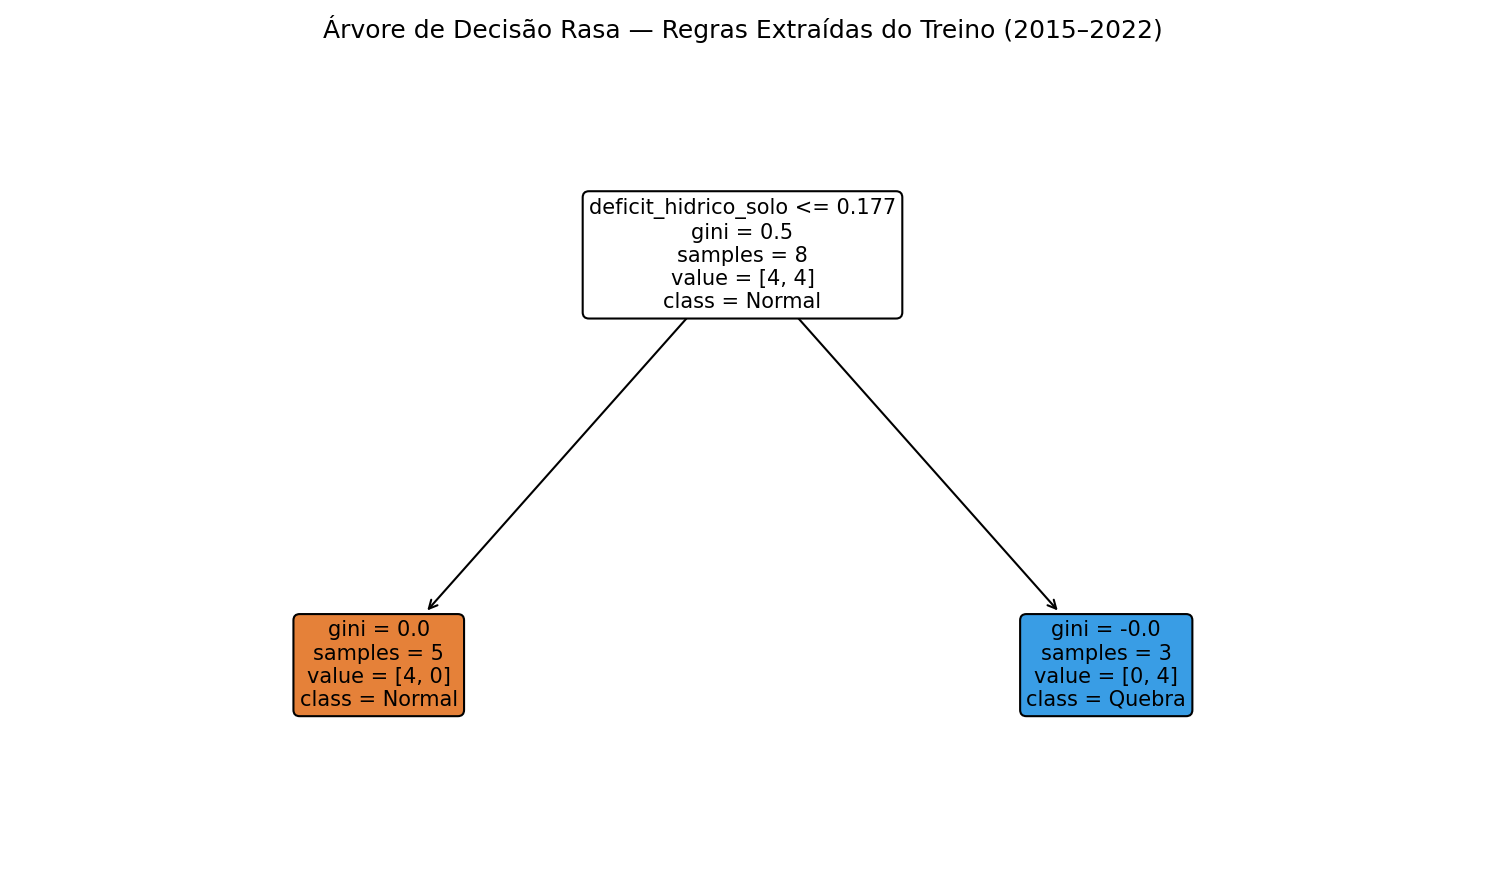

Gráfico salvo em docs/assets/arvore_decisao_s5.png!


In [7]:
dt_model = pipelines["Decision Tree (Rasa)"]["classifier"]

plt.figure(figsize=(10, 6), dpi=150)
plot_tree(
    dt_model,
    feature_names=FEATURES,
    class_names=["Normal", "Quebra"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Árvore de Decisão Rasa — Regras Extraídas do Treino (2015–2022)", fontsize=12)
plt.tight_layout()
plt.savefig("../docs/assets/arvore_decisao_s5.png")
plt.show()
print("Gráfico salvo em docs/assets/arvore_decisao_s5.png!")

## 6. Persistência dos Resultados para o Diário da Sprint 5

Exportamos as tabelas geradas para CSV em , garantindo rastreabilidade completa e dados prontos para alimentar o .

In [8]:
df_res_teste.to_csv("../models/s5_comparativo_teste.csv", index=False)
df_tab_backtest.to_csv("../models/s5_comparativo_backtest.csv", index=False)
print("Resultados exportados em ../models/s5_comparativo_teste.csv e ../models/s5_comparativo_backtest.csv!")

Resultados exportados em ../models/s5_comparativo_teste.csv e ../models/s5_comparativo_backtest.csv!
